In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(
    "../data/raw/pima-indians-diabetes.csv",
    header=None,
    names=columns
)

print("Kích thước:", df.shape)

display(df.head())

Kích thước: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
correlation_matrix = df.corr()

display(correlation_matrix.round(2))

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.00,0.13,0.14,-0.08,-0.07,0.02,-0.03,0.54,0.22
Glucose,0.13,1.00,0.15,0.06,0.33,0.22,0.14,0.26,0.47
BloodPressure,0.14,0.15,1.00,0.21,0.09,0.28,0.04,0.24,0.07
SkinThickness,-0.08,0.06,0.21,1.00,0.44,0.39,0.18,-0.11,0.07
Insulin,-0.07,0.33,0.09,0.44,1.00,0.20,0.19,-0.04,0.13
BMI,0.02,0.22,0.28,0.39,0.20,1.00,0.14,0.04,0.29
DiabetesPedigreeFunction,-0.03,0.14,0.04,0.18,0.19,0.14,1.00,0.03,0.17
Age,0.54,0.26,0.24,-0.11,-0.04,0.04,0.03,1.00,0.24
Outcome,0.22,0.47,0.07,0.07,0.13,0.29,0.17,0.24,1.00


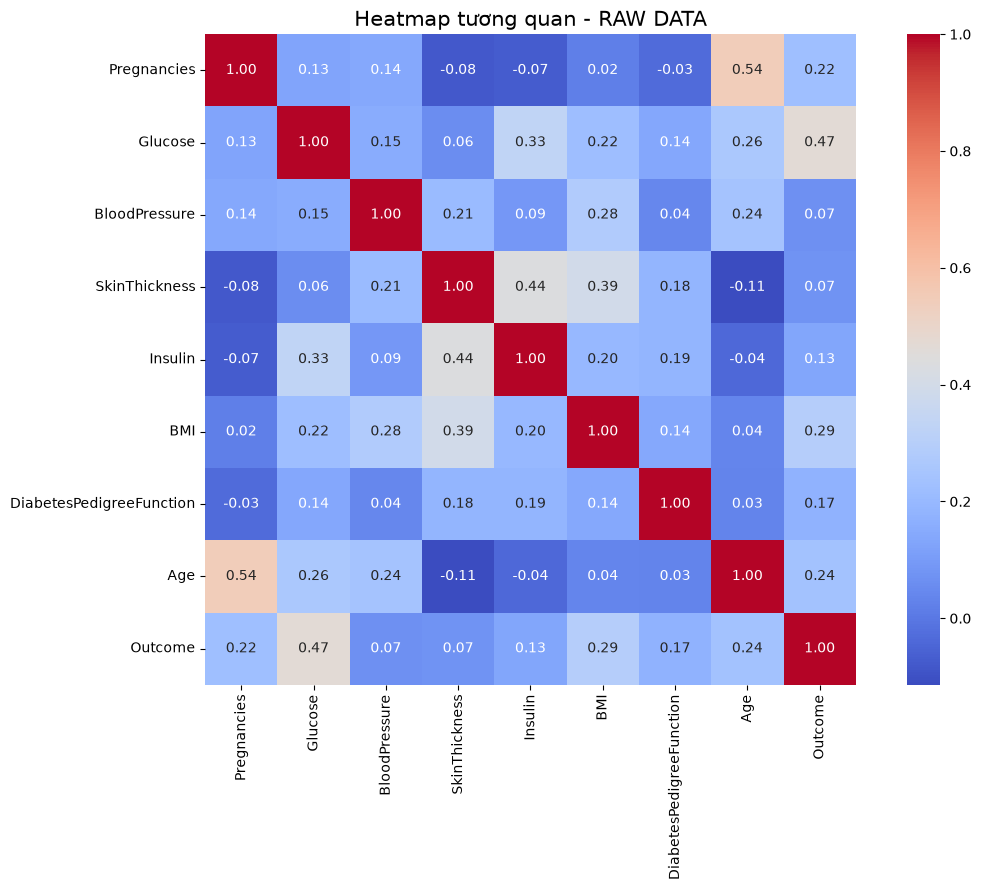

In [3]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)

plt.title(
    "Heatmap tương quan - RAW DATA",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "../images/eda_raw/04_correlation_heatmap_raw.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [4]:
outcome_correlation = (
    correlation_matrix["Outcome"]
    .drop("Outcome")
    .sort_values(ascending=False)
)

outcome_table = pd.DataFrame({
    "Feature": outcome_correlation.index,
    "Correlation_with_Outcome": outcome_correlation.round(3).values
})

display(outcome_table)

,Feature,Correlation_with_Outcome
0,Glucose,0.467
1,BMI,0.293
2,Age,0.238
3,Pregnancies,0.222
4,DiabetesPedigreeFunction,0.174
5,Insulin,0.131
6,SkinThickness,0.075
7,BloodPressure,0.065


In [6]:
print("NHẬN XÉT TƯƠNG QUAN VỚI OUTCOME")
print()

print("- Glucose có tương quan dương cao nhất với Outcome.")
print("- BMI có mức tương quan dương đứng thứ hai.")
print("- Age và Pregnancies cũng có tương quan dương với Outcome.")
print("- BloodPressure và SkinThickness có tương quan tuyến tính khá thấp với Outcome.")

print()
print("Kết luận:")
print("Glucose là feature có mức tương quan tuyến tính nổi bật nhất với Outcome trong dữ liệu raw.")
print("Tương quan không chứng minh quan hệ nhân quả.")

NHẬN XÉT TƯƠNG QUAN VỚI OUTCOME

- Glucose có tương quan dương cao nhất với Outcome.
- BMI có mức tương quan dương đứng thứ hai.
- Age và Pregnancies cũng có tương quan dương với Outcome.
- BloodPressure và SkinThickness có tương quan tuyến tính khá thấp với Outcome.

Kết luận:
Glucose là feature có mức tương quan tuyến tính nổi bật nhất với Outcome trong dữ liệu raw.
Tương quan không chứng minh quan hệ nhân quả.


In [7]:
outcome_table.to_csv(
    "../reports/outcome_correlation.csv",
    index=False,
    encoding="utf-8-sig"
)

correlation_matrix.to_csv(
    "../reports/correlation_matrix.csv",
    encoding="utf-8-sig"
)

print("Đã lưu kết quả")

Đã lưu kết quả
